<center><h1> ETI195 - Ética para Ciencia de Datos y Estadística </h1><center>
<center><h2> Taller Sumativo 3: Modelos interpretables y xAI <h2><center>  




# `Instrucciones generales`

Esta es la parte III del proyecto, considerá ultizar tus resultados anteriores
y reciclar el código anterior.

## `Temas formales`

**Modalidad**: Grupos de 3 personas.

**Formato de entrega:** El trabajo debe entregarse a través de Canvas, tanto en formato Jupyter ejecutable (.ipynb) como en formato PDF.

**Formalidades de las respuestas:**
- Citas: APA 7.
- Se espera buena ortografía y redacción, con respuestas en tono académico.
- No respondan con simples "si" o "no" , considera argumentar tu respuestas y justificar con bibliografía si lo estimas necesario.

## `Recomendaciones`

- Asistan a los talleres formativos, revisen los ejemplos de código y consulten sus dudas con sus ayudantes.

- **Lean la rúbrica antes de hacer su tarea.**

## `Integridad académica y uso de IA`

El uso de asistentes de IA sigue los lineamientos de integridad académica del curso, con las siguientes excepciones:

- Pueden usar IA para consultar por bugs y entender mejor el código.
- Pueden usar IA para generar las representaciones visuales que estimen convenientes.

Si tienen dudas sobre el uso de IA o la citación de código externo, no duden en preguntar. Pueden usar libremente los códigos de los talleres formativos. <3


In [20]:
!pip install lime


[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [21]:
# Coloque aquí todas las importaciones que considere necesarias.
from transformers import pipeline
from lime.lime_text import LimeTextExplainer
import numpy as np
import matplotlib.pyplot as plt


# Parte 1: Interpretabilidad local con LIME

## Motivación

Un modelo de clasificación de texto puede tener buen desempeño agregado y aun así fallar sistemáticamente ante ciertos tipos de lenguaje: eufemismos, tecnicismos, formas indirectas de comunicar una noticia, o lenguaje cargado políticamente. Estas fallas suelen ser invisibles si solo miramos métricas globales o si confiamos ciegamente en el sistema. LIME permite explorar una predicción individual y preguntar: ¿qué palabras llevaron al modelo a decidir esto? Esto es especialmente relevante cuando el texto que se clasifica admite múltiples interpretaciones, tiene una carga social relevante y, en definitiva, forma parte de un sistema con consecuencias reales sobre las personas.

En esta parte van a diseñar un pequeño experimento: eligen un contexto de riesgo asociado a su proyecto, construyen frases que pongan a prueba ese riesgo específico, y usan LIME para ver si el modelo efectivamente falla (o no) de la manera que hipotetizaron.

## Parte 1.1: Contexto

Lo primero que deben hacer es definir el contexto de su análisis. Dependiendo del proyecto que su grupo haya escogido, elijan un escenario en el que un sistema sociotécnico relacionado con su dataset tuviera que clasificar lenguaje, y en el que un error de clasificación tuviera una consecuencia concreta. Por ejemplo:

- **CIRI**: un sistema que clasifica declaraciones oficiales de gobiernos para detectar lenguaje que minimiza o niega violaciones a los derechos humanos.

- **Breast Cancer**: un sistema que analiza cómo se comunica un diagnóstico a pacientes.

- **CASEN**: un sistema que clasifica comunicaciones de resultados de ayudas sociales.

**Responder:**

0. Explica los conceptos clave: XAI, LIME y SHAP y lo que se busca hacer con estos en el contexto del taller.

1. Describan el escenario de riesgo que eligieron: ¿qué tipo de frases van a analizar y por qué esas frases son relevantes para ese escenario? Creen o recopilen al menos 10 frases.


#### 0. Conceptos a explicar:

**XAI**:


**LIME**: Como vimos en clases, las siglas significan **Explicaciones Locales**, Interpretables у Agnósticas al Modelo. Permite explicar de manera sencilla las predicciopnes de modelos de forma individual.

**SHAP**: es un modelo agnóstico cuyo objetivo es explicar cómo cada variable de entrada, se va ponderando y así afectandola predicción de un modelo. Si bien da explicaciones local, al igual que LIME, también entrega explicaciones globales.


#### 1. Como hemos trabajado con el dataset de Breast Cancer, decidimos usar el mismo ejemplo que suguieren, es decir, **un sistema que analiza como se comunica un diagnostico a pacientes**.

Las frases a analizar son las siguientes.

- 'Lamento infromar que su diagnóstico es cancer de mama.'
- 'Tengo un malas noticias, la enfermedad fue detectada.'
- 'No tengo buenas noticias, la enfermedad fue detectada.'
- 'El examen confirmó que lo que estás experimentando, tienes cancer de mama.'
- 'Los resultados del laboratorio y las imágenes traen las noticias que temíamos.',
- 'Lamento informar este diagnóstico, pero no estás sola.'
- 'Lamento informar este diagnóstico, pero no estás solo.'
- 'El diagnóstico es cancer de mama, trazaremos un plan de acción.'
- 'Los resultados de la biopsia llegaron y muestran que tienes cancer.'
- 'Gracias por venir. He estado revisado tus resultados y estos confirman la enfermedad.'

Consideramos diferentes frases, algunas que tal vez tratan de 'suavizar' la noticia y otras que son más directas. También quisimos presentarle al modelos la misma frase pero con distinto género para ver que asigna. Como hipótesis pensamos que el modelo tenga una tendencia a un 'sentimiento' más negativo. Nosotros entendemos lo fuerte que puede ser para una persona recibir algún diagnóstico entonces lo asociamos con algo negativo o desfavorable.

## Parte 1.2: Aplicación de LIME

1. Carguen el modelo BETO de análisis de sentimientos.

2. Obtengan la predicción del modelo para cada frase y comparen los resultados con su hipótesis de 1.1: ¿se cumplió lo que esperaban?

3. Apliquen LIME para obtener la explicación local de al menos 5 frases, priorizando aquellas donde el modelo se comportó de forma inesperada o donde identifiquen un problema ético. Si no encuentran ningún problema, justifiquen esa conclusión. Para cada una, visualicen las contribuciones de cada palabra mediante un gráfico de barras.

4. Interpreten los resultados: ¿qué palabras están dominando cada predicción? ¿El modelo se apoya en las palabras que ustedes esperaban, o en otras? ¿Identifican un problema ético o social en los resultados?

In [22]:
# 1. Cargamos el modelo BETO

clasificador = pipeline(
    "sentiment-analysis",
    model="finiteautomata/beto-sentiment-analysis",
    tokenizer="finiteautomata/beto-sentiment-analysis"
)

config.json:   0%|          | 0.00/841 [00:00<?, ?B/s]

C:\Users\const\AppData\Local\Programs\Python\Python312\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\const\.cache\huggingface\hub\models--finiteautomata--beto-sentiment-analysis. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
C:\Users\const\AppData\Local\Programs\Python\Python312\Lib\site-packages\hu

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  440MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/528 [00:00<?, ?B/s]

... (2 outputs left out)

vocab.txt:   0%|          | 0.00/242k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/481k [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/67.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

In [23]:
# 2. Obtenemos la predicción del modelo para cada frase y comparamos los resultados con la hipótesis

frases = ['Lamento infromar que su diagnóstico es cancer de mama.',
          'Tengo un malas noticias, la enfermedad fue detectada.',
          'No tengo buenas noticias, la enfermedad fue detectada.',
          'El examen confirmó que lo que estás experimentando, tienes cancer de mama.',
          'Los resultados del laboratorio y las imágenes traen las noticias que temíamos.',
          'Lamento informar este diagnóstico, pero no estás sola.',
          'Lamento informar este diagnóstico, pero no estás solo.',
          'El diagnóstico es cancer de mama, trazaremos un plan de acción.',
          'Los resultados de la biopsia llegaron y muestran que tienes cancer.',
          'Gracias por venir. He estado revisado tus resultados y estos confirman la enfermedad.']

print("Predicciones del modelo\n")
for frase in frases:
    resultado = clasificador(frase)[0]
    print(f"Frase     : {frase}")
    print(f"Sentimiento: {resultado['label']} (confianza: {resultado['score']:.2%})\n")

Predicciones del modelo

Frase     : Lamento infromar que su diagnóstico es cancer de mama.
Sentimiento: NEG (confianza: 81.31%)

Frase     : Tengo un malas noticias, la enfermedad fue detectada.
Sentimiento: NEU (confianza: 61.12%)

Frase     : No tengo buenas noticias, la enfermedad fue detectada.
Sentimiento: NEU (confianza: 99.68%)

Frase     : El examen confirmó que lo que estás experimentando, tienes cancer de mama.
Sentimiento: NEG (confianza: 98.39%)

Frase     : Los resultados del laboratorio y las imágenes traen las noticias que temíamos.
Sentimiento: NEG (confianza: 99.86%)

Frase     : Lamento informar este diagnóstico, pero no estás sola.
Sentimiento: POS (confianza: 98.96%)

Frase     : Lamento informar este diagnóstico, pero no estás solo.
Sentimiento: NEU (confianza: 97.19%)

Frase     : El diagnóstico es cancer de mama, trazaremos un plan de acción.
Sentimiento: NEU (confianza: 99.83%)

Frase     : Los resultados de la biopsia llegaron y muestran que tienes cancer.
Sen

Podríamos decir que no se cumplió la hipótesis. Para 5/10 frases arrojó un sentiempiento de neutralidad. Para 4/10 un sentimiento negativo y 1/10 arrojó que era positivo.

In [27]:
# 3. Aplicamos LIME para obtener la explicación local de al menos 5 frases
def predecir_proba(textos):
    """
    Envuelve el pipeline de Hugging Face en el formato que espera LIME:
    recibe una lista de textos y retorna una matriz (n_textos x 3) con
    probabilidades para las clases NEG, NEU y POS.

    Aproximación: la probabilidad de la clase predicha es el score del modelo;
    el resto se distribuye uniformemente entre las otras dos clases.
    """
    etiquetas = ["NEG", "NEU", "POS"]  # orden fijo requerido por LimeTextExplainer
    resultados = clasificador(list(textos), top_k=None)
    probas = []
    for r in resultados:
        scores = {d["label"]: d["score"] for d in r}
        probas.append([scores[e] for e in etiquetas])
    return np.array(probas)

# Instanciamos el explicador LIME con los nombres de las clases del modelo
explainer = LimeTextExplainer(class_names=["NEG", "NEU", "POS"])

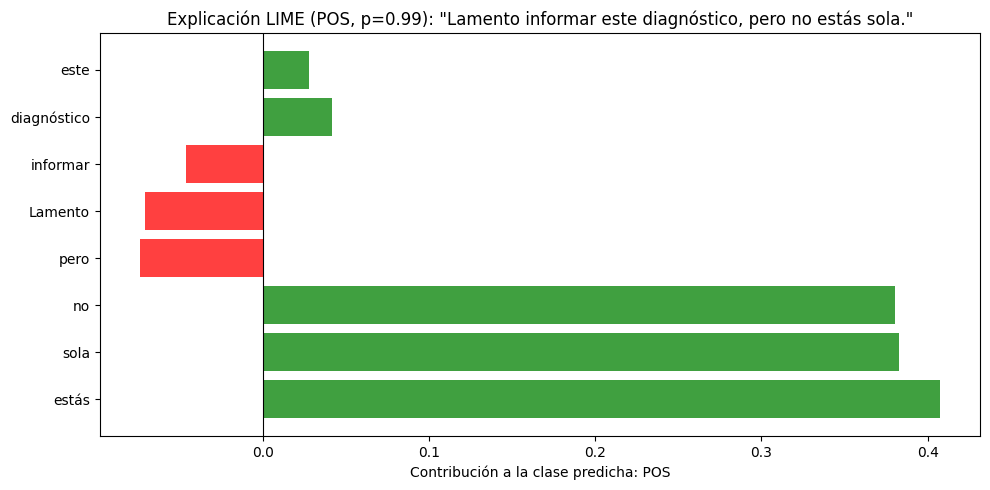

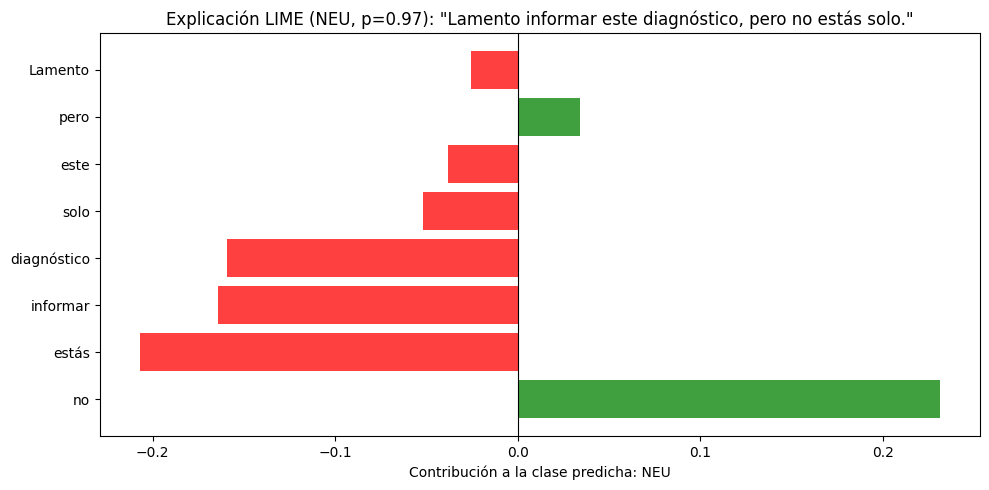

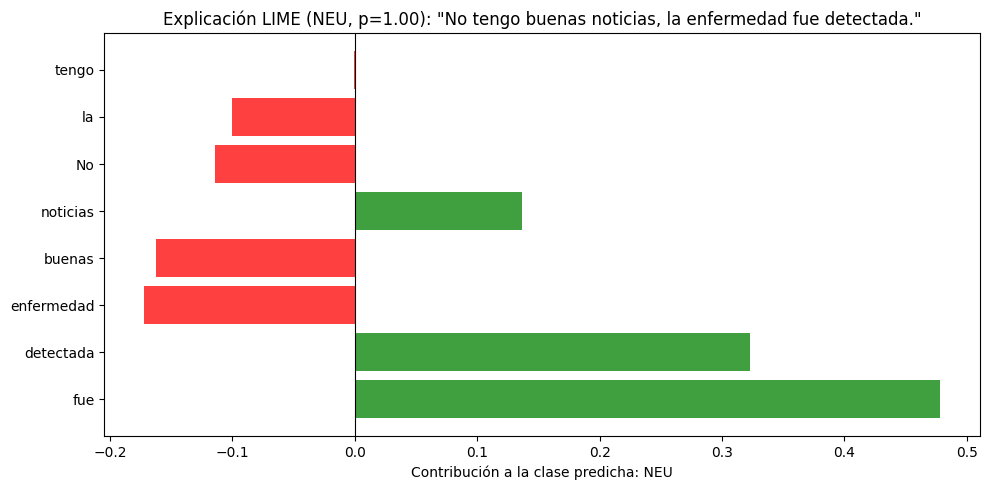

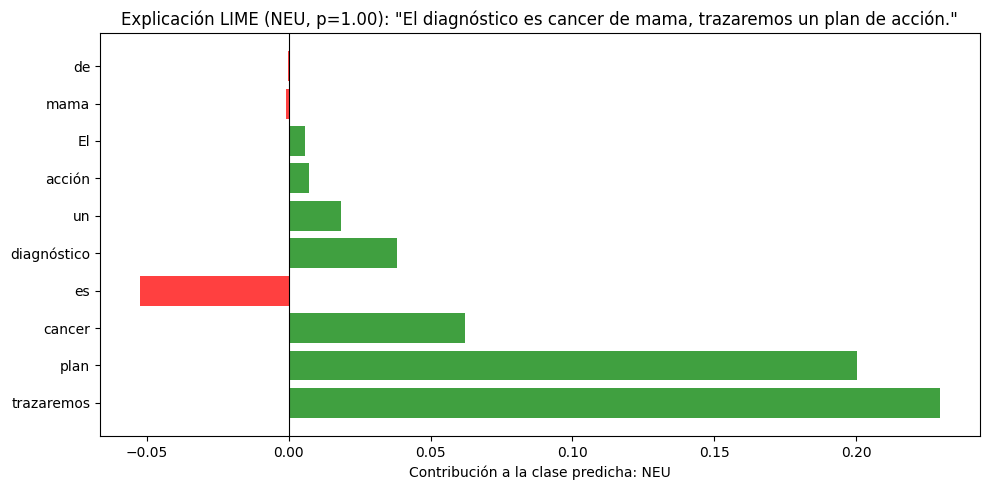

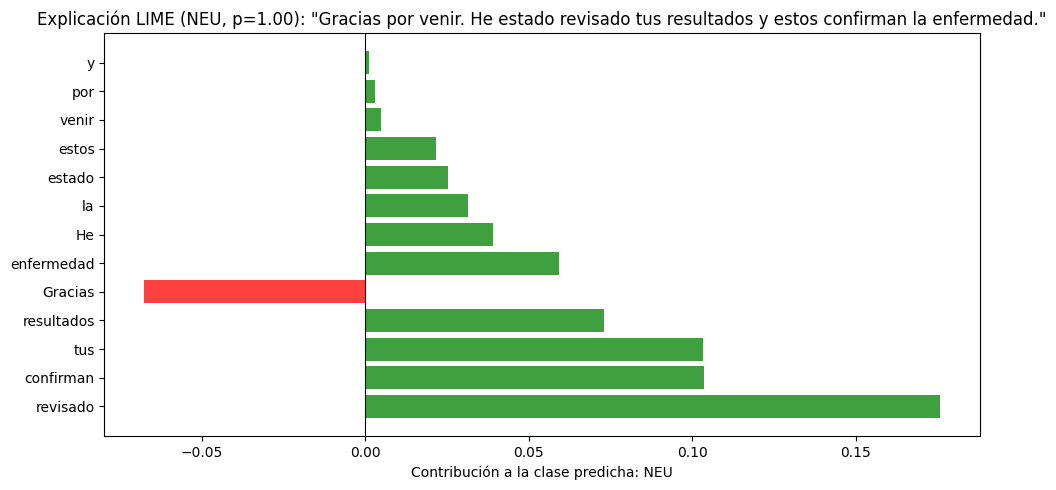

In [28]:
frases = ['Lamento informar este diagnóstico, pero no estás sola.',
         'Lamento informar este diagnóstico, pero no estás solo.',
         'No tengo buenas noticias, la enfermedad fue detectada.',
         'El diagnóstico es cancer de mama, trazaremos un plan de acción.',
         'Gracias por venir. He estado revisado tus resultados y estos confirman la enfermedad.']

for f in range(len(frases)):

  frase_a_explicar = frases[f].strip()

  # Clase predicha por el modelo
  probs = predecir_proba([frase_a_explicar])[0]
  clase_idx = int(np.argmax(probs))
  nombre_clase = explainer.class_names[clase_idx]

  # Obtener explicación para  esa clase
  exp = explainer.explain_instance(
      frase_a_explicar,
      predecir_proba,
      labels=(clase_idx,),
      num_features=len(frase_a_explicar.split()),
      num_samples=500
  )


  # Extraemos los pesos (contribuciones) de cada palabra
  explicacion = exp.as_list(label=clase_idx)
  palabras = [item[0] for item in explicacion]
  pesos    = [item[1] for item in explicacion]

  # Barras empujan hacia la clase que se busca predecir
  fig, ax = plt.subplots(figsize=(10, 5))
  colores = ['green' if p > 0 else 'red' for p in pesos] # los colores se asignan para ver que palabras empujan a la clase predicha.
  ax.barh(palabras, pesos, color=colores, alpha=0.75)
  ax.set_xlabel(f'Contribución a la clase predicha: {nombre_clase}')
  ax.set_title(f'Explicación LIME ({nombre_clase}, p={probs[clase_idx]:.2f}): "{frase_a_explicar}"')
  ax.axvline(x=0, color='black', linestyle='-', linewidth=0.8)
  plt.tight_layout()
  plt.show()

#### 4. Interpretación de resultados

¿qué palabras están dominando cada predicción? ¿El modelo se apoya en las palabras que ustedes esperaban, o en otras? ¿Identifican un problema ético o social en los resultados?

Con relación a si el modelo se apoya o no en las palabra que esperabamos, podríamos decir que sí y que no.

Para las frases 'Lamento informar este diagnóstico, pero no estás sola' y 'Lamento informar este diagnóstico, pero no estás solo', llama la atención en para uno la palabra 'estás' o 'sola/o' tienen diferencias en la predicción que muestra el modelo.

En los siguientes gráficos, sí esperabamos que palabras como 'enfermedad' o 'diagnostico' tuvieran una predicción más negativa, pero la última frase llama la atención de que si bien puede ser un poco más neutral, no quital el hecho de que se este diagnosticando una enfermedad y la mayoría de palabras tienen una predicción positiva pero una palabras como 'gracias', no la tiene.

Un problema es la carencia de comprensión humana-afectiva del modelo sobre el contexto de las frases. El modelo recibe frases muy duras sobre el diagnóstico de una enfermedad grave como el cáncer y para un ser humano sin importar que tan empática esté redactada la frase, la noticia sigue siendo profundamente negativa por la repercución que tendrá para la vida de la persona, por el contrario para modelo un "no estás sola" hace cambiar la clasificación a positiva, lo que genera un gran problema ético, clasificar de esa manera minimiza la gravedad de la noticia y trivializa la información.

Si este tipo de modelo se instaurara sin la supervición del personal de salud y entregara ayuda emocional exclusivamente a quienes clasifiquen como negativos,sería un desastre, ya que como vimos anteriormente, todas las frases dan el mismo diagnóstico y solo 4 de 10 calsificaron como NEG, por lo tanto, un sistema con ese con ese modelo desestimaría a las y los pacientes en una situación altamente vulnerable, convirtiendose en un problema social de alto impacto.

# Parte 2 : Explicabilidad de Random Forest con SHAP


En esta segunda parte del taller continuarán el trabajo anterior. Usando la limpieza y estandarización que ya realizaron, entrenen ahora un modelo Random Forest. Recuerden que, como mínimo, en la parte anterior debieron haber realizado los siguientes pasos:

2.1 Carga y limpieza de datos

- Revisión de qué columnas tienen nulos o datos faltantes y manejo de estos mediante: 0, botar fila/columna, o imputación de media.

- Revisión del tipo de dato del dataset y de los cambios realizados, si corresponde.

- Codificación de las variables categóricas, ya sea con label encoder, one-hot encoder, dummies, o mapeo manual en caso de columnas binarias.


## `Librerias`

In [ ]:
import pandas as pd
import numpy as np
import shap

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, accuracy_score, ConfusionMa
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler,MinMaxScaler


2.2 División del conjunto de datos
- separe del conjunto total los predictores y **la variable objetivo **
- Utilice train_test_split para obtener el conjunto de prueba y entrenamiento.

(La variable objetivo no difiere de la utilizada en el taller anterior)



2.3 Estandarización
- Estandarice los datos numéricos con StandarScaler o Minmax
- Justifique brevemente su elección






2.4 Clasificador Random Forest y métrica de evaluación
- Entrenen un Random Forest, seleccionen un número de estimadores y entreguen las predicciones del modelo.
- Comenten los resultados de la matriz de confusión y del reporte de clasificación. Expliquen las consecuencias de aplicar ese modelo específico en el área que abarca su proyecto.

2.5 Resultado y explicaciones con SHAP
- Comenta los beneficios y perjuicios que puede tener una herramienta como SHAP, en general y aterriza al caso de los datos trabajados
- Obten los valores shap.Visualiza el summary plot. Comenta los resultados.
- Analiza que features son importantes para la predicción y que puede influir en que estas tengan mayor influencia. Considera en tu explicación la relevancia de los resultados en el contexto.

- Preguntas guía para tu respuesta : ¿Qué aporta conocer los valores SHAP? ¿Es una herramienta suficiente en sí misma o puede apoyarse con otras? ¿Cómo afecta la preparación de los datos a las predicciones y su posterior explicación? ¿Es importante tener acceso a ambas interpretaciónes (global y local) en este caso?